# Пример обучения нейросети для задачи регрессии

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [2]:
torch.manual_seed(42) # воспроизводимость вычислений


### генерация данных

In [3]:
# генерация данных
X = torch.linspace(-2 * torch.pi, 2* torch.pi, 200).unsqueeze(1)  # (200, 1)

# Целевая переменная: y = sin(x)
y = torch.sin(X)    # Форма (200, 1)
print(X.shape, y.shape)

torch.Size([200, 1]) torch.Size([200, 1])


### Модель

In [4]:
class SineNet(nn.Module):
    """Модель предсказания sin(x)"""

    def __init__(self, input_dim, output_dim, hidden_layer_dim=32):

        super().__init__()


        # Первый полносвязный слой
        self.fc1 = nn.Linear(in_features=input_dim, out_features=hidden_layer_dim)

        # функция активации
        self.relu = nn.ReLU()

        # Второй полносвязный слой
        self.fc2 = nn.Linear(in_features=hidden_layer_dim, out_features=output_dim)

    def forward(self, x):
        """Порядок вычислений"""
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)

        return x

In [5]:
input_dim = 1
output_dim = 1

model = SineNet(input_dim=input_dim, output_dim=output_dim)
model

SineNet(
  (fc1): Linear(in_features=1, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)

In [6]:
# обучаемые параметры
for name, param in model.named_parameters():
    print(name, param.shape)

fc1.weight torch.Size([32, 1])
fc1.bias torch.Size([32])
fc2.weight torch.Size([1, 32])
fc2.bias torch.Size([1])


### Прогон батча (forward pass)

In [7]:
batch_size = 50
x_batch = X[:batch_size]
y_batch = y[:batch_size]

predictions = model(x_batch)


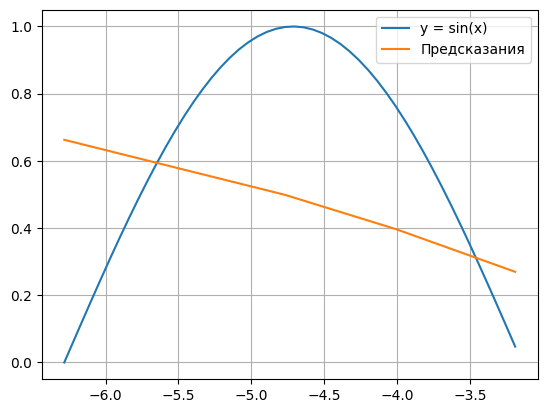

In [8]:
plt.plot(x_batch, y_batch, label='y = sin(x)')
plt.plot(x_batch, predictions.detach().numpy(), label='Предсказания')
plt.legend()
plt.grid()

### Инициализация Loss функции и расчет ошибки

In [9]:
loss_fn = nn.MSELoss()

# расчет ошибки
loss = loss_fn(predictions, y_batch)
loss.item()

0.1307360976934433

### Оптимизатор

In [10]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01) # будет менять параметры модели в ходе обучения
optimizer

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)

### Шаг обновления весов модели: 

> zero_grad -> forward -> loss -> backward -> step

In [11]:
# снимок весов и значений loss до шага оптимизатора, чтобы потом сравнить
weight_before = model.fc1.weight.clone().detach()
loss_before = loss.item()

# Обновление
optimizer.zero_grad()  # обнуление градиентов
loss.backward()  # расчет новых градиентов по всем весам
optimizer.step() # обновление весов

In [12]:
weight_after = model.fc1.weight
# Проверяем, равны ли тензоры до и после шага
print(torch.equal(weight_before, weight_after))

# Считаем средний размер изменения весов
print((weight_after - weight_before).abs().mean().item()) 

False
0.005312496796250343


In [13]:
n_steps = 1000

for step in range(n_steps):
    optimizer.zero_grad()                # 1. Обнуляем градиенты
    predictions = model(x_batch)         # 2. Forward: получаем свежие предсказания
    loss = loss_fn(predictions, y_batch) # 3. Считаем loss на текущих весах
    loss.backward()                      # 4. Вычисляем новые градиенты
    optimizer.step()                     # 5. Делаем шаг обновления весов

print("Loss до начала цикла:", loss_before)
print(f"Loss после {n_steps} шагов:", loss.item())

Loss до начала цикла: 0.1307360976934433
Loss после 1000 шагов: 0.0007078945636749268


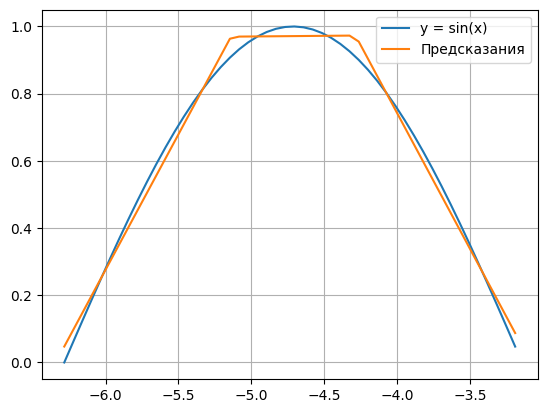

In [14]:
with torch.no_grad():
    final_predictions = model(x_batch)
    plt.plot(x_batch, y_batch, label='y = sin(x)')
    plt.plot(x_batch, final_predictions.detach().numpy(), label='Предсказания')
    plt.legend()
    plt.grid()
 